# Unsupervised Learning — Complete Teaching Notebook

**Purpose:** A detailed, classroom-ready guide to unsupervised machine learning using Python, NumPy, pandas, Matplotlib, Seaborn and scikit-learn.

## Learning outcomes
By the end of this notebook, students should be able to:
- Explain unsupervised learning and distinguish it from supervised learning.
- Inspect and prepare data when no target/label column is provided.
- Explain similarity, distance, scaling and dimensionality.
- Apply and interpret K-Means, hierarchical clustering and DBSCAN.
- Evaluate clusters using inertia, silhouette score and visual inspection.
- Apply Principal Component Analysis (PCA) for dimensionality reduction.
- Understand anomaly detection with Isolation Forest.
- Understand association-rule mining and market-basket analysis.
- Build a reproducible workflow and explain limitations of unsupervised results.

> **Important:** Unsupervised learning discovers structure in the data. A discovered cluster is not automatically a meaningful real-world category. Interpretation and domain validation are essential.


## 1. What is Unsupervised Learning?

Unsupervised learning is a machine-learning approach in which an algorithm is given input data **without a supplied target label**. The algorithm attempts to discover patterns, structure, groups, relationships or unusual observations.

Examples:
- Group customers with similar purchasing behaviour.
- Group news articles by content similarity.
- Find unusual bank transactions.
- Reduce thousands of measurements to a smaller set of informative dimensions.
- Discover products that are frequently purchased together.

### Supervised vs. unsupervised learning

| Aspect | Supervised learning | Unsupervised learning |
|---|---|---|
| Target label | Available | Not supplied |
| Main goal | Predict a known target | Discover hidden structure |
| Typical tasks | Regression, classification | Clustering, dimensionality reduction, anomaly detection, association rules |
| Evaluation | Often compare predictions with known answers | Often indirect; use internal metrics, stability and domain judgement |

### Common unsupervised tasks
1. **Clustering:** group similar observations.
2. **Dimensionality reduction:** represent data with fewer variables while retaining useful structure.
3. **Anomaly detection:** identify observations that differ substantially from the majority.
4. **Association-rule mining:** discover items or events that frequently occur together.

There is no universal “correct answer” in many unsupervised tasks. Results depend on the features, distance measure, algorithm and hyperparameters.


## 2. Set up the Python environment

Install the packages if they are not already available:

```bash
pip install numpy pandas matplotlib seaborn scikit-learn scipy mlxtend
```

`mlxtend` is used later for association-rule mining. If it is unavailable in your environment, the clustering, PCA and anomaly-detection sections can still run.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid")
np.random.seed(42)

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Setup complete.")


NumPy: 2.4.6
pandas: 3.0.3
Setup complete.


## 3. Understand the data before modelling

In unsupervised learning, there may be no target column to separate from the features. First identify what one row represents and what each column measures.

Typical inspection steps:
- `head()` to inspect sample records.
- `shape` to inspect the number of rows and columns.
- `info()` to inspect data types and missing values.
- `describe()` to inspect numerical distributions.
- `nunique()` to inspect the number of unique values.
- Check duplicate records and impossible values.

Do not automatically use every column. Names, database IDs, transaction IDs and arbitrary codes may not describe similarity in a meaningful way.


In [2]:
# Create a small example customer dataset
customers = pd.DataFrame({
    "CustomerID": range(1001, 1011),
    "Age": [22, 25, 24, 45, 49, 52, 31, 34, 36, 29],
    "AnnualIncome": [25, 28, 27, 75, 82, 88, 45, 48, 52, 42],
    "SpendingScore": [80, 75, 85, 25, 30, 20, 55, 60, 50, 65],
    "VisitsPerMonth": [8, 7, 9, 2, 3, 2, 5, 6, 4, 6]
})

display(customers.head())
print("Shape:", customers.shape)
print("\nData types and non-null counts:")
customers.info()


,CustomerID,Age,AnnualIncome,SpendingScore,VisitsPerMonth
0,1001,22,25,80,8
1,1002,25,28,75,7
2,1003,24,27,85,9
3,1004,45,75,25,2
4,1005,49,82,30,3


Shape: (10, 5)

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerID      10 non-null     int64
 1   Age             10 non-null     int64
 2   AnnualIncome    10 non-null     int64
 3   SpendingScore   10 non-null     int64
 4   VisitsPerMonth  10 non-null     int64
dtypes: int64(5)
memory usage: 532.0 bytes


In [3]:
display(customers.describe())
print("\nUnique values per column:")
display(customers.nunique().to_frame("unique_count"))
print("Duplicate rows:", customers.duplicated().sum())


,CustomerID,Age,AnnualIncome,SpendingScore,VisitsPerMonth
count,10.00000,10.000,10.000000,10.000000,10.000000
mean,1005.50000,34.700,51.200000,54.500000,5.200000
std,3.02765,10.688,23.126704,23.148074,2.440401
min,1001.00000,22.000,25.000000,20.000000,2.000000
25%,1003.25000,26.000,31.500000,35.000000,3.250000
50%,1005.50000,32.500,46.500000,57.500000,5.500000
75%,1007.75000,42.750,69.250000,72.500000,6.750000
max,1010.00000,52.000,88.000000,85.000000,9.000000



Unique values per column:


,unique_count
CustomerID,10
Age,10
AnnualIncome,10
SpendingScore,10
VisitsPerMonth,8


Duplicate rows: 0


## 4. Features, observations and the absence of a target

Suppose a customer table contains:
- Age
- Annual income
- Spending score
- Visits per month

Each row represents one customer. The algorithm compares customers using the selected feature values and tries to form groups.

`CustomerID` is an identifier, not a behavioural measurement. Including it in a distance calculation can create meaningless differences. We will exclude it.

**Key principle:** the absence of a target does not mean that data preparation is unnecessary. Feature selection, missing-value treatment, encoding and scaling can strongly change the discovered structure.


In [4]:
# Select meaningful numeric features; exclude the identifier
customer_features = customers[[
    "Age", "AnnualIncome", "SpendingScore", "VisitsPerMonth"
]].copy()

display(customer_features.head())


,Age,AnnualIncome,SpendingScore,VisitsPerMonth
0,22,25,80,8
1,25,28,75,7
2,24,27,85,9
3,45,75,25,2
4,49,82,30,3


## 5. Why scaling matters

Many clustering methods use distances. A feature measured in thousands can dominate a feature measured between 0 and 10.

For example, annual income may range from 20 to 100 (thousands), while visits per month may range from 1 to 10. The feature with the larger numerical spread may contribute more to Euclidean distance.

### Standardization
For each feature:

\[
z = \frac{x - \mu}{\sigma}
\]

The transformed feature has mean approximately 0 and standard deviation approximately 1.

### Min-max scaling
\[
x' = \frac{x - x_{min}}{x_{max} - x_{min}}
\]

This usually maps values into the interval [0, 1].

- StandardScaler is a common choice for K-Means and PCA.
- MinMaxScaler is useful when a bounded range is desirable.
- RobustScaler can be useful when extreme values distort mean and standard deviation.
- Tree-based methods generally do not depend on distance in the same way.

Fit the scaler on the data being analysed. In predictive workflows, fit transformations on training data only.


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customer_features)

scaled_customers = pd.DataFrame(
    X_scaled,
    columns=customer_features.columns,
    index=customer_features.index
)

display(scaled_customers.head().round(2))
print("Means after standardization:")
print(scaled_customers.mean().round(3))
print("\nStandard deviations:")
print(scaled_customers.std().round(3))


,Age,AnnualIncome,SpendingScore,VisitsPerMonth
0,-1.25,-1.19,1.16,1.21
1,-0.96,-1.06,0.93,0.78
2,-1.06,-1.10,1.39,1.64
3,1.02,1.08,-1.34,-1.38
4,1.41,1.40,-1.12,-0.95


Means after standardization:
Age              -0.0
AnnualIncome     -0.0
SpendingScore     0.0
VisitsPerMonth   -0.0
dtype: float64

Standard deviations:
Age               1.054
AnnualIncome      1.054
SpendingScore     1.054
VisitsPerMonth    1.054
dtype: float64


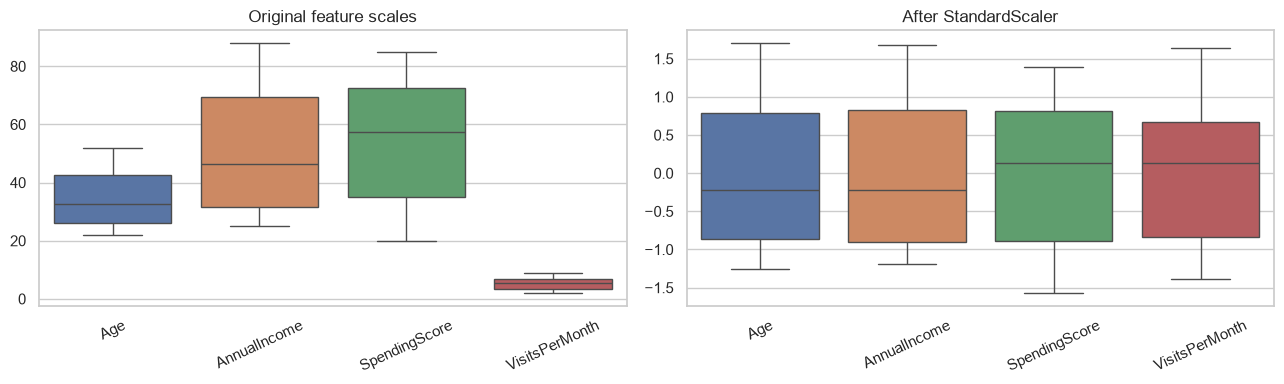

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=customer_features, ax=axes[0])
axes[0].set_title("Original feature scales")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(data=scaled_customers, ax=axes[1])
axes[1].set_title("After StandardScaler")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


## 6. Similarity and distance

Clustering algorithms need some way to decide which observations are similar.

### Euclidean distance
Straight-line distance between two points:

\[
d(x,y) = \sqrt{\sum_{j=1}^{p}(x_j-y_j)^2}
\]

### Manhattan distance
Sum of absolute coordinate differences:

\[
d(x,y) = \sum_{j=1}^{p}|x_j-y_j|
\]

### Cosine similarity
Measures the angle between two vectors. It is often useful for text vectors, where direction can matter more than magnitude.

Distance is not a universal definition of similarity. The best metric depends on the data and problem. For mixed numerical and categorical data, ordinary Euclidean distance may not be appropriate without careful encoding or a mixed-data distance.


In [7]:
from sklearn.metrics import pairwise_distances

sample = scaled_customers.iloc[:4]
euclidean = pairwise_distances(sample, metric="euclidean")
manhattan = pairwise_distances(sample, metric="manhattan")

print("Euclidean distance matrix:")
display(pd.DataFrame(euclidean, index=sample.index, columns=sample.index).round(2))

print("Manhattan distance matrix:")
display(pd.DataFrame(manhattan, index=sample.index, columns=sample.index).round(2))


Euclidean distance matrix:


,0,1,2,3
0,0.00,0.59,0.53,4.83
1,0.59,0.00,0.98,4.28
2,0.53,0.98,0.00,5.07
3,4.83,4.28,5.07,0.00


Manhattan distance matrix:


,0,1,2,3
0,0.00,1.09,0.95,9.64
1,1.09,0.00,1.46,8.55
2,0.95,1.46,0.00,10.01
3,9.64,8.55,10.01,0.00


# Part A — Clustering

## 7. What is clustering?

Clustering groups observations so that points in the same group are relatively similar, while points in different groups are relatively dissimilar.

Examples:
- Customer segmentation.
- Grouping documents by topic.
- Grouping similar product usage patterns.
- Grouping geographic locations.

A cluster label such as `0`, `1` or `2` is simply an identifier assigned by the algorithm. Cluster 2 is not inherently better or more important than cluster 1.

### Common clustering algorithms
- K-Means: partitions observations around cluster centres.
- Hierarchical clustering: builds a hierarchy of nested groups.
- DBSCAN: finds dense regions and can label isolated observations as noise.


## 8. K-Means clustering

K-Means aims to divide observations into **K clusters**. Each cluster is represented by its centroid (the mean position of the points assigned to that cluster).

### Basic process
1. Choose the number of clusters, K.
2. Initialize K centroids.
3. Assign each observation to its nearest centroid.
4. Recalculate each centroid as the mean of its assigned observations.
5. Repeat assignment and update until assignments stabilize or a stopping condition is reached.

### Objective: inertia / within-cluster sum of squares

\[
\text{Inertia} = \sum_{k=1}^{K}\sum_{x_i \in C_k} ||x_i-\mu_k||^2
\]

K-Means tries to minimize this quantity.

### Important properties
- K must be specified before fitting.
- Sensitive to feature scaling and outliers.
- Works best when clusters are reasonably compact and roughly spherical in the chosen feature space.
- Different initializations can lead to different solutions; `n_init` runs multiple initializations.
- It can struggle with irregular shapes or clusters with very different densities.


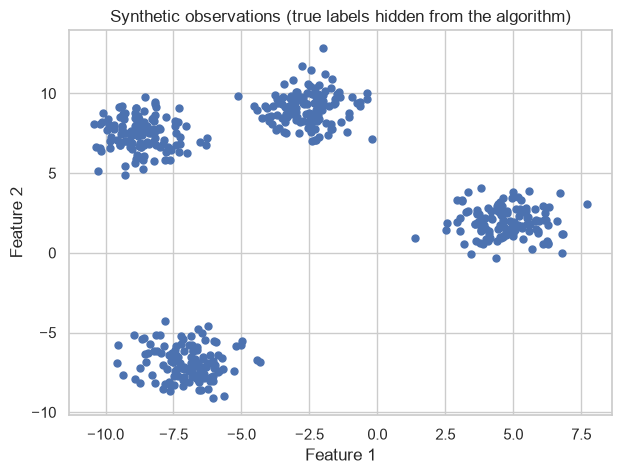

In [13]:
# Create a synthetic dataset with visible groups
X_blobs, true_groups = make_blobs(
    n_samples=500,
    centers=4,
    cluster_std=1.0,
    random_state=42
)

blobs_df = pd.DataFrame(X_blobs, columns=["Feature_1", "Feature_2"])

plt.figure(figsize=(7, 5))
plt.scatter(blobs_df["Feature_1"], blobs_df["Feature_2"], s=25)
plt.title("Synthetic observations (true labels hidden from the algorithm)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


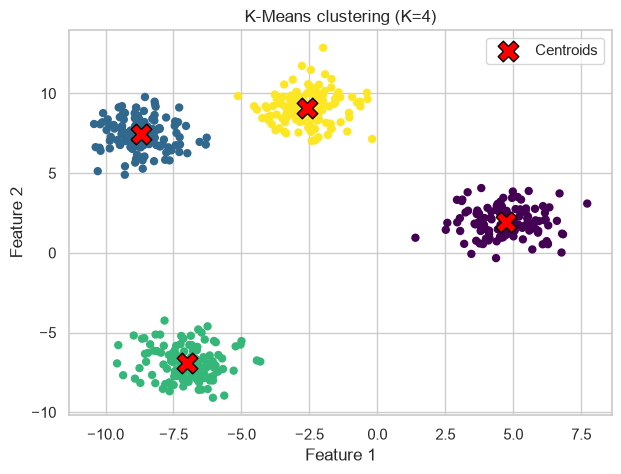

In [15]:
# Fit K-Means
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_blobs)

blobs_df["Cluster"] = kmeans_labels

plt.figure(figsize=(7, 5))
plt.scatter(
    blobs_df["Feature_1"], blobs_df["Feature_2"],
    c=blobs_df["Cluster"], cmap="viridis", s=25
)
centres = kmeans.cluster_centers_
plt.scatter(centres[:, 0], centres[:, 1], marker="X", s=220,
            c="red", edgecolor="black", label="Centroids")
plt.title("K-Means clustering (K=4)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()


In [ ]:
print("Cluster counts:")
display(blobs_df["Cluster"].value_counts().sort_index().to_frame("observations"))

print("Centroids:")
display(pd.DataFrame(centres, columns=["Feature_1", "Feature_2"]))
print("Inertia:", round(kmeans.inertia_, 2))


## 9. Choosing K: the Elbow Method

Inertia generally decreases as K increases because more clusters allow points to be closer to their assigned centroids. Therefore, simply choosing the K with the smallest inertia would usually favour too many clusters.

The elbow method:
1. Fit K-Means for a range of K values.
2. Record inertia for each K.
3. Plot K against inertia.
4. Look for a bend where adding more clusters produces diminishing improvement.

The elbow can be ambiguous. It is a heuristic, not a mathematical guarantee of the correct number of clusters.


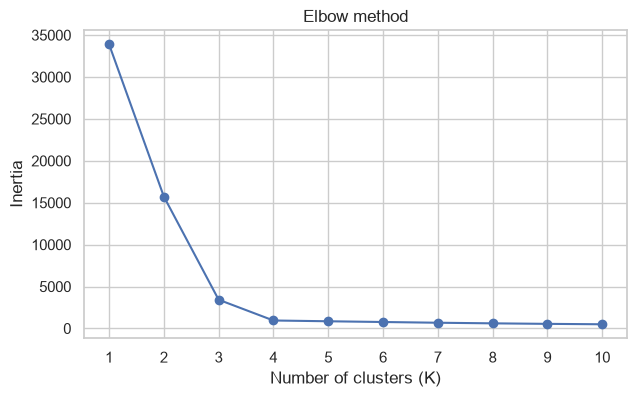

In [16]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_blobs)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.show()


## 10. Silhouette score

The silhouette score measures how well each observation fits its assigned cluster compared with the nearest alternative cluster.

For observation i:

\[
s(i) = \frac{b(i)-a(i)}{\max(a(i),b(i))}
\]

- `a(i)`: average distance from i to points in its own cluster.
- `b(i)`: lowest average distance from i to points in another cluster.

Interpretation:
- Close to +1: observation is well matched to its own cluster.
- Around 0: observation lies near a cluster boundary.
- Below 0: observation may be closer to another cluster.

The overall silhouette score is the average across observations. It is not meaningful in the same way for every clustering structure; use it alongside visual and domain analysis.


In [17]:
silhouette_results = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_blobs)
    silhouette_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X_blobs, labels)
    })

display(pd.DataFrame(silhouette_results).round(3))


,K,Inertia,Silhouette
0,2,15737.084,0.596
1,3,3426.257,0.761
2,4,948.890,0.791
3,5,856.472,0.663
4,6,768.039,0.561
5,7,681.352,0.441
6,8,608.538,0.337


## 11. Other internal clustering metrics

### Davies–Bouldin index
Compares within-cluster scatter with separation between clusters. **Lower is generally better.**

### Calinski–Harabasz score
Compares between-cluster dispersion with within-cluster dispersion. **Higher is generally better.**

These metrics can favour particular cluster shapes or sizes. They should not be treated as proof that a clustering is meaningful.


In [18]:
labels = kmeans_labels

print("Silhouette score:", round(silhouette_score(X_blobs, labels), 3))
print("Davies-Bouldin index:", round(davies_bouldin_score(X_blobs, labels), 3))
print("Calinski-Harabasz score:", round(calinski_harabasz_score(X_blobs, labels), 2))


Silhouette score: 0.791
Davies-Bouldin index: 0.294
Calinski-Harabasz score: 5742.04


## 12. Interpreting clusters

After clustering, return to the original feature units and describe the groups.

Useful questions:
- How many observations are in each cluster?
- What are the average and median feature values per cluster?
- Which features distinguish the groups?
- Are the groups actionable and understandable?
- Are the groups stable if the data sample or algorithm settings change?

Do not interpret standardized cluster-centre values as if they were original units. Use the original dataset to build profiles.


In [19]:
# Customer segmentation example with K-Means
customer_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
customer_labels = customer_kmeans.fit_predict(X_scaled)

customer_segmented = customers.copy()
customer_segmented["Cluster"] = customer_labels

print("Cluster sizes:")
display(customer_segmented["Cluster"].value_counts().sort_index())

print("Cluster profiles (original units):")
profile = customer_segmented.groupby("Cluster")[[
    "Age", "AnnualIncome", "SpendingScore", "VisitsPerMonth"
]].mean().round(1)
display(profile)


Cluster sizes:


Cluster
0    3
1    4
2    3
Name: count, dtype: int64

Cluster profiles (original units):


,Age,AnnualIncome,SpendingScore,VisitsPerMonth
Cluster,,,,
0,48.7,81.7,25.0,2.3
1,32.5,46.8,57.5,5.2
2,23.7,26.7,80.0,8.0


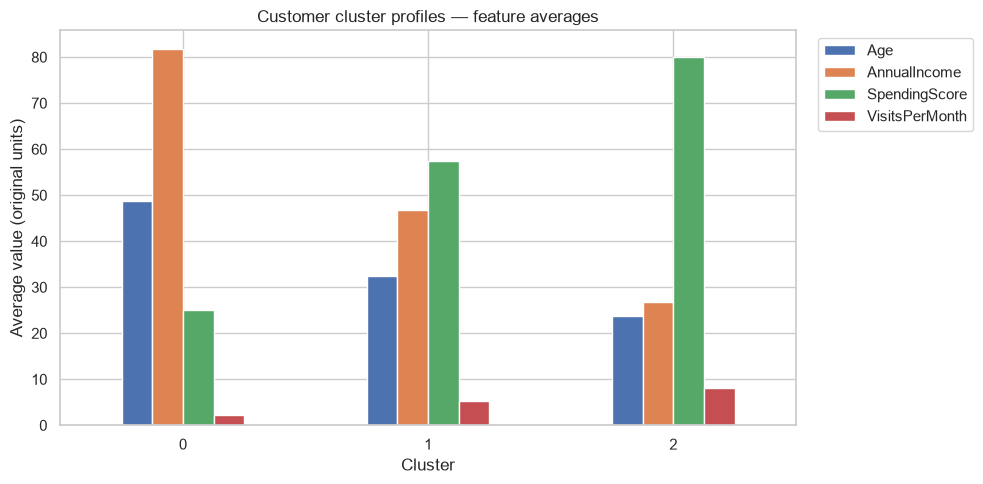

In [20]:
profile.plot(kind="bar", figsize=(10, 5))
plt.title("Customer cluster profiles — feature averages")
plt.ylabel("Average value (original units)")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 13. Hierarchical clustering

Hierarchical clustering builds a hierarchy of clusters, often represented by a dendrogram.

### Agglomerative approach
This is a bottom-up process:
1. Start with each observation as its own cluster.
2. Find the two closest clusters.
3. Merge them.
4. Repeat until the desired number of clusters or one overall cluster remains.

### Linkage methods
- **Single:** minimum distance between points in two clusters; can create chaining.
- **Complete:** maximum distance; tends to create compact clusters.
- **Average:** average pairwise distance.
- **Ward:** merges clusters that produce the smallest increase in within-cluster variance; commonly used with Euclidean distance.

Hierarchical clustering can be useful when nested group structure is important. It can be computationally expensive for large datasets.


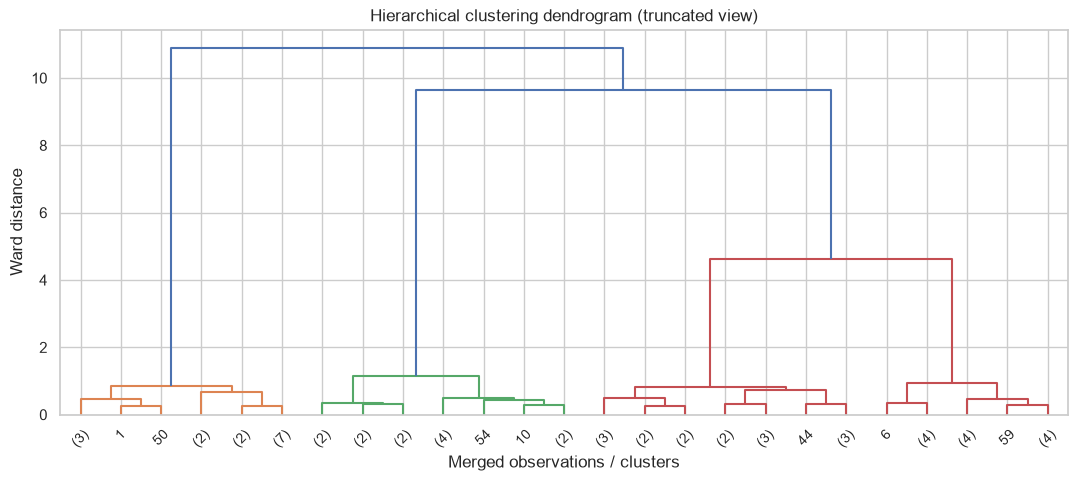

In [21]:
# Use a manageable sample for the dendrogram
from scipy.cluster.hierarchy import linkage, dendrogram

X_hier_sample = StandardScaler().fit_transform(X_blobs[:60])
Z = linkage(X_hier_sample, method="ward")

plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode="lastp", p=25, leaf_rotation=45)
plt.title("Hierarchical clustering dendrogram (truncated view)")
plt.xlabel("Merged observations / clusters")
plt.ylabel("Ward distance")
plt.show()


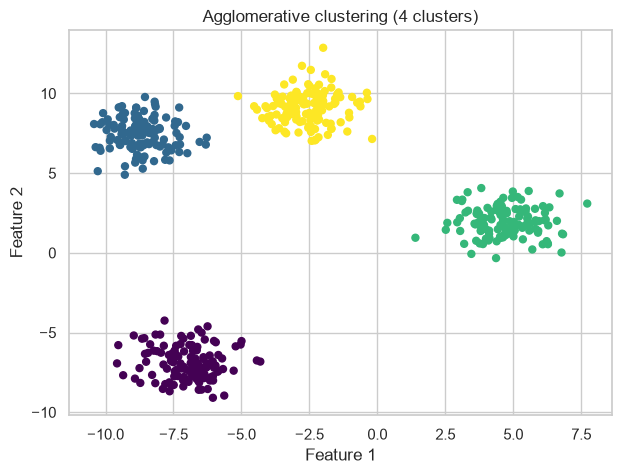

In [22]:
hierarchical = AgglomerativeClustering(n_clusters=4, linkage="ward")
hier_labels = hierarchical.fit_predict(X_blobs)

plt.figure(figsize=(7, 5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=hier_labels, cmap="viridis", s=25)
plt.title("Agglomerative clustering (4 clusters)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


## 14. DBSCAN — Density-Based Spatial Clustering

DBSCAN groups observations in dense regions and marks isolated observations as noise.

Two important parameters:
- `eps`: neighbourhood radius.
- `min_samples`: minimum number of nearby observations required for a point to be considered a core point.

### Point types
- **Core point:** has at least `min_samples` points in its eps-neighbourhood (including itself).
- **Border point:** is near a core point but does not itself have enough neighbours.
- **Noise point:** is not assigned to a cluster.

### Strengths
- Does not require the number of clusters in advance.
- Can identify irregularly shaped clusters.
- Can label noise/outliers.

### Limitations
- Sensitive to `eps` and `min_samples`.
- Struggles when clusters have very different densities.
- Distance and scaling still matter.


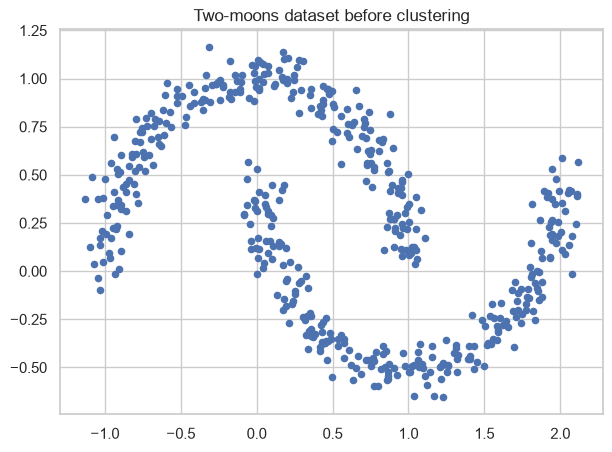

In [23]:
# Create non-spherical data
X_moons, _ = make_moons(n_samples=500, noise=0.07, random_state=42)

plt.figure(figsize=(7, 5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], s=20)
plt.title("Two-moons dataset before clustering")
plt.show()


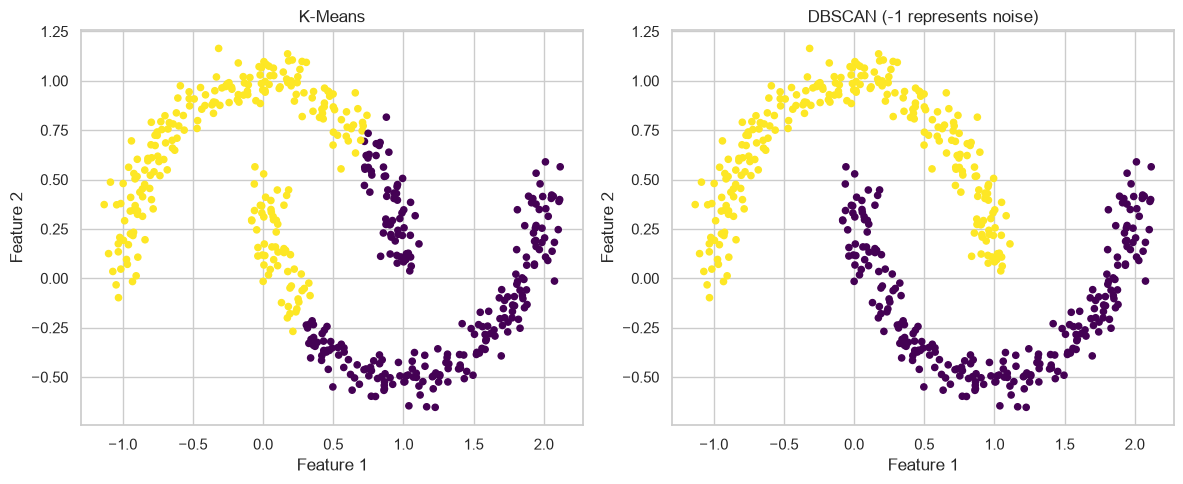

DBSCAN labels: [0 1]
Noise observations: 0


In [24]:
# K-Means is not ideal for every shape
moon_kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
moon_kmeans_labels = moon_kmeans.fit_predict(X_moons)

# DBSCAN can identify the curved dense regions
moon_dbscan = DBSCAN(eps=0.18, min_samples=5)
moon_dbscan_labels = moon_dbscan.fit_predict(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=moon_kmeans_labels, cmap="viridis", s=20)
axes[0].set_title("K-Means")
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=moon_dbscan_labels, cmap="viridis", s=20)
axes[1].set_title("DBSCAN (-1 represents noise)")
for ax in axes:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

print("DBSCAN labels:", np.unique(moon_dbscan_labels))
print("Noise observations:", np.sum(moon_dbscan_labels == -1))


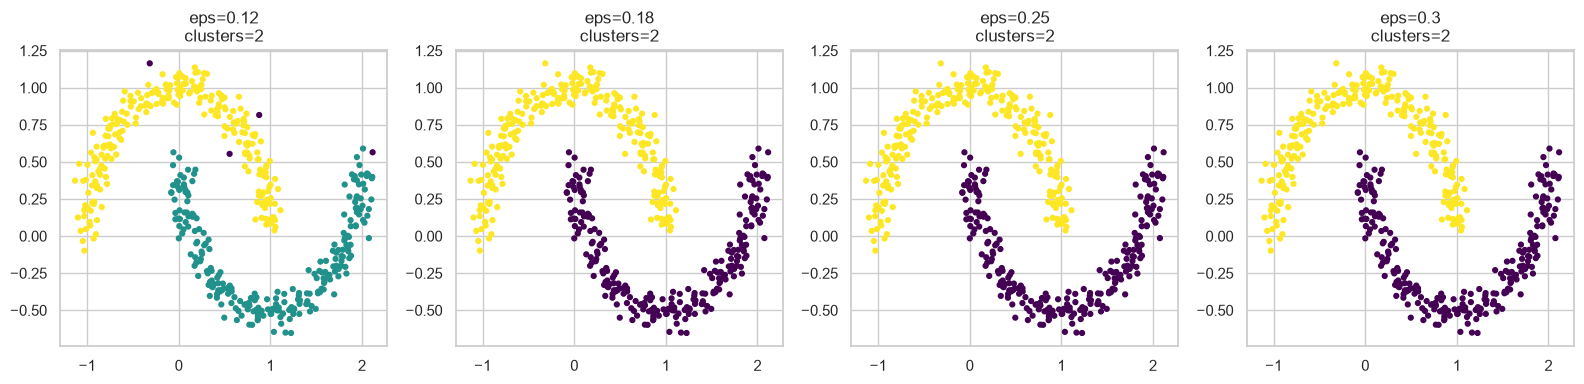

In [25]:
# Explore DBSCAN parameter sensitivity
settings = [(0.12, 5), (0.18, 5), (0.25, 5), (0.30, 5)]
fig, axes = plt.subplots(1, len(settings), figsize=(16, 4))

for ax, (eps_value, min_samples_value) in zip(axes, settings):
    labels = DBSCAN(eps=eps_value, min_samples=min_samples_value).fit_predict(X_moons)
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=labels, cmap="viridis", s=12)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    ax.set_title(f"eps={eps_value}\nclusters={n_clusters}")
plt.tight_layout()
plt.show()


## 15. Comparing clustering algorithms

| Algorithm | Must choose K? | Finds irregular shapes? | Handles noise explicitly? | Key considerations |
|---|---:|---:|---:|---|
| K-Means | Yes | Usually no | No | Scaling, initialization, compact clusters |
| Agglomerative | Usually choose cut / cluster count | Depends on linkage | No dedicated noise label | Dendrogram, linkage, computational cost |
| DBSCAN | No | Yes | Yes | Density, eps, min_samples, scaling |

No algorithm is best for every dataset. Compare results using:
- Visual inspection where possible.
- Internal metrics where appropriate.
- Cluster profiles and domain expertise.
- Stability under resampling or parameter changes.
- Whether the groups support a useful decision.


# Part B — Dimensionality Reduction

## 16. What is dimensionality reduction?

A dataset with many features can be difficult to visualize, store, interpret and model. Dimensionality reduction represents data using fewer dimensions.

Reasons to use it:
- Visualize high-dimensional observations in 2D or 3D.
- Reduce redundancy among correlated variables.
- Compress data.
- Reduce noise or simplify downstream modelling.
- Help address computational challenges.

Two broad approaches:
- **Feature selection:** keep a subset of original features.
- **Feature extraction:** create new variables from combinations or transformations of original features.

PCA is a widely used linear feature-extraction method.


## 17. Principal Component Analysis (PCA)

PCA transforms correlated features into a new set of uncorrelated variables called principal components.

- The first principal component captures the largest possible variance.
- The second captures the largest remaining variance while being orthogonal to the first.
- Further components continue this process.

PCA is sensitive to feature scale, so standardization is often important when features use different units.

PCA is unsupervised: it does not use target labels when finding components. High variance does not necessarily mean high predictive or business importance.


In [26]:
# Use the scaled customer data
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_
pca_summary = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(explained))],
    "ExplainedVarianceRatio": explained,
    "CumulativeVariance": np.cumsum(explained)
})
display(pca_summary.round(3))


,Component,ExplainedVarianceRatio,CumulativeVariance
0,PC1,0.977,0.977
1,PC2,0.022,0.998
2,PC3,0.001,1.000
3,PC4,0.000,1.000


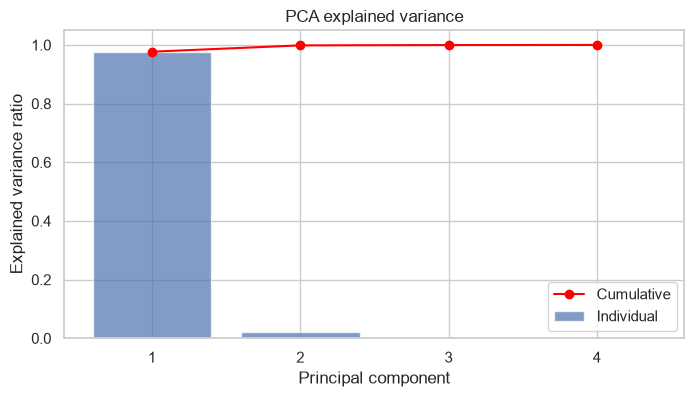

In [27]:
plt.figure(figsize=(8, 4))
plt.bar(range(1, len(explained)+1), explained, alpha=0.7, label="Individual")
plt.plot(range(1, len(explained)+1), np.cumsum(explained), marker="o",
         color="red", label="Cumulative")
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA explained variance")
plt.xticks(range(1, len(explained)+1))
plt.legend()
plt.show()


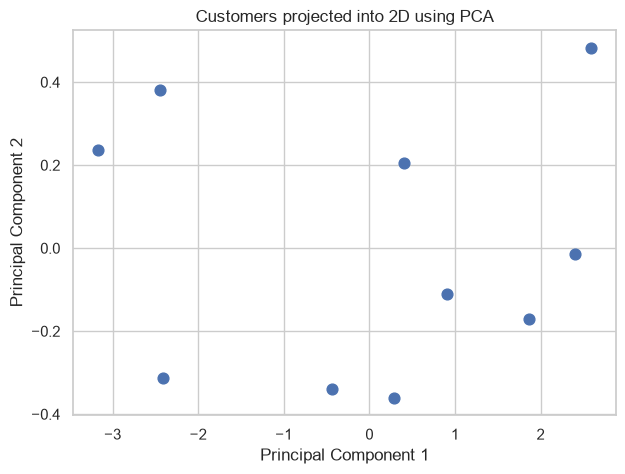

Variance retained by two components: 99.85 %


In [28]:
# Project observations into two principal components
pca_2d = PCA(n_components=2)
customer_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(customer_2d[:, 0], customer_2d[:, 1], s=60)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customers projected into 2D using PCA")
plt.show()

print("Variance retained by two components:",
      round(pca_2d.explained_variance_ratio_.sum() * 100, 2), "%")


## 18. PCA loadings and interpretation

A principal component is a weighted combination of the original features. The weights are often called loadings.

A large positive or negative loading indicates that a feature contributes strongly to that component. The sign of a component can be flipped without changing the underlying PCA solution, so interpret relative patterns rather than treating positive/negative direction as inherently meaningful.


,PC1,PC2
Age,-0.500,0.502
AnnualIncome,-0.502,0.423
SpendingScore,0.504,0.206
VisitsPerMonth,0.494,0.726


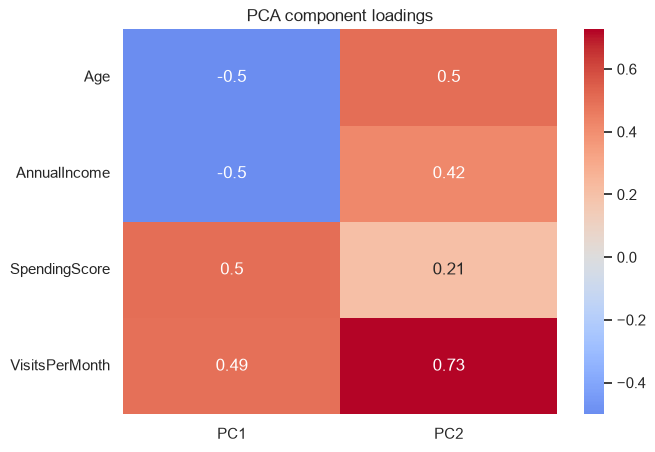

In [29]:
loadings = pd.DataFrame(
    pca_2d.components_.T,
    index=customer_features.columns,
    columns=["PC1", "PC2"]
)
display(loadings.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(loadings, annot=True, cmap="coolwarm", center=0)
plt.title("PCA component loadings")
plt.show()


## 19. PCA followed by clustering

PCA can be used before clustering, especially when features are highly correlated or dimensionality is high.

However:
- PCA may discard low-variance directions that are important for separating groups.
- The number of components is a modelling choice.
- Compare clustering in the original scaled feature space and reduced space.
- Do not assume that a 2D PCA plot displays all the structure in the original data.


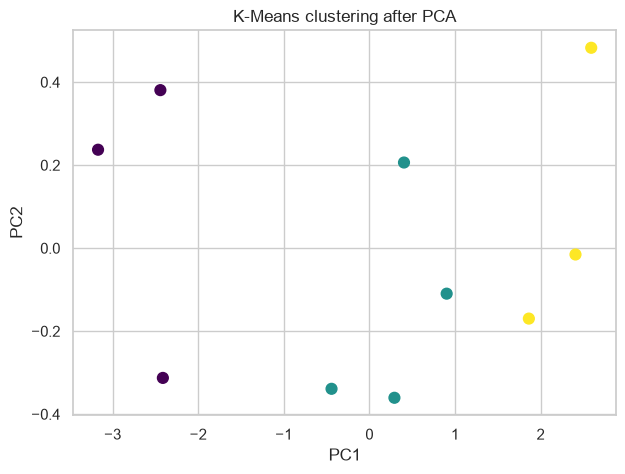

In [30]:
# Demonstration: retain two components, then cluster
pca_for_cluster = PCA(n_components=2, random_state=42)
X_reduced = pca_for_cluster.fit_transform(X_scaled)

kmeans_pca = KMeans(n_clusters=3, random_state=42, n_init=10)
pca_cluster_labels = kmeans_pca.fit_predict(X_reduced)

plt.figure(figsize=(7, 5))
plt.scatter(X_reduced[:, 0], X_reduced[:, 1],
            c=pca_cluster_labels, cmap="viridis", s=60)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means clustering after PCA")
plt.show()


# Part C — Anomaly Detection

## 20. What is anomaly detection?

Anomaly detection attempts to identify observations that differ substantially from typical patterns.

Examples:
- Unusual financial transactions.
- Unexpected machine sensor readings.
- Suspicious login activity.
- Manufacturing defects.
- Abnormal network traffic.

An anomaly is not necessarily an error or fraud. It is an observation that deserves investigation.

Methods include:
- Statistical rules and distance-based approaches.
- Isolation Forest.
- Local Outlier Factor.
- One-Class SVM.

Anomaly detection is often treated as an unsupervised task, although some methods can use labelled examples.


## 21. Isolation Forest

Isolation Forest identifies anomalies by isolating observations through random feature selection and split values.

The intuition:
- Unusual points are often easier to isolate.
- They tend to require fewer random splits than typical observations.
- The algorithm produces an anomaly score and a prediction.

In scikit-learn:
- `predict()` returns `1` for inliers and `-1` for outliers.
- `contamination` represents the expected proportion of outliers used to set the threshold; it is not a guarantee that exactly that proportion are truly anomalous.
- `random_state` supports reproducibility.

Use domain knowledge to investigate flagged observations.


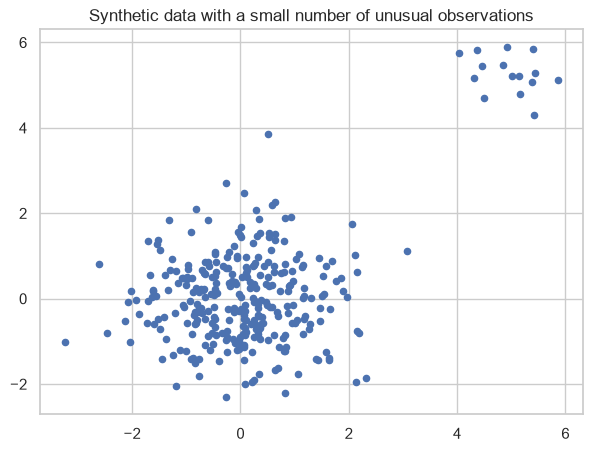

In [31]:
# Generate mostly normal observations plus a few unusual points
rng = np.random.RandomState(42)
normal_points = rng.normal(loc=0, scale=1, size=(300, 2))
unusual_points = rng.uniform(low=4, high=6, size=(15, 2))
X_anomaly = np.vstack([normal_points, unusual_points])

plt.figure(figsize=(7, 5))
plt.scatter(X_anomaly[:, 0], X_anomaly[:, 1], s=20)
plt.title("Synthetic data with a small number of unusual observations")
plt.show()


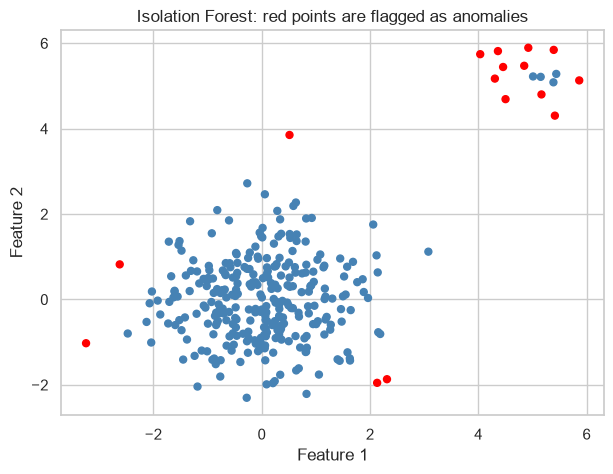

Flagged observations: 16


,Feature_1,Feature_2,Prediction,AnomalyScore
37,-2.619745,0.821903,-1,-0.018196
104,0.515048,3.852731,-1,-0.034803
110,2.314659,-1.867265,-1,-0.011981
131,-3.241267,-1.024388,-1,-0.037130
142,2.133033,-1.952088,-1,-0.002273


In [32]:
iso_forest = IsolationForest(
    contamination=0.05,
    random_state=42
)

anomaly_predictions = iso_forest.fit_predict(X_anomaly)
anomaly_scores = iso_forest.decision_function(X_anomaly)

anomaly_df = pd.DataFrame(X_anomaly, columns=["Feature_1", "Feature_2"])
anomaly_df["Prediction"] = anomaly_predictions
anomaly_df["AnomalyScore"] = anomaly_scores

plt.figure(figsize=(7, 5))
colors = np.where(anomaly_predictions == -1, "red", "steelblue")
plt.scatter(X_anomaly[:, 0], X_anomaly[:, 1], c=colors, s=25)
plt.title("Isolation Forest: red points are flagged as anomalies")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

print("Flagged observations:", (anomaly_predictions == -1).sum())
display(anomaly_df[anomaly_df["Prediction"] == -1].head())


# Part D — Association Rule Mining

## 22. What is association-rule mining?

Association-rule mining finds items or events that frequently occur together.

A classic example is market-basket analysis:
- Customers who buy bread may also buy butter.
- Customers who buy a particular product may often buy a related product.

A rule has the form:

\[
A \Rightarrow B
\]

This means that transactions containing itemset A are often also associated with itemset B. It does **not** prove that A causes B.

### Key measures

**Support**
\[
support(A \Rightarrow B) = P(A \cup B)
\]

Fraction of all transactions containing both A and B.

**Confidence**
\[
confidence(A \Rightarrow B) = P(B|A)
= \frac{support(A \cup B)}{support(A)}
\]

Among transactions containing A, the fraction that also contain B.

**Lift**
\[
lift(A \Rightarrow B) =
\frac{confidence(A \Rightarrow B)}{support(B)}
\]

- Lift > 1: A and B occur together more often than expected under independence.
- Lift = 1: no association beyond independence.
- Lift < 1: they occur together less often than expected under independence.

Association rules can be affected by item popularity, transaction size and data collection practices.


## 23. Prepare transaction data

Association-rule algorithms commonly expect one-hot encoded transaction data: one row per transaction and one column per item, with True/1 indicating that the item is present.

We will create a small illustrative basket dataset.


In [33]:
transactions = [
    ["Bread", "Milk", "Butter"],
    ["Bread", "Diapers", "Beer", "Eggs"],
    ["Milk", "Diapers", "Beer", "Cola"],
    ["Bread", "Milk", "Diapers", "Beer"],
    ["Bread", "Milk", "Diapers", "Cola"],
    ["Bread", "Milk", "Butter"],
    ["Milk", "Eggs"],
    ["Bread", "Diapers", "Beer"],
    ["Bread", "Milk", "Eggs"],
    ["Milk", "Butter"]
]

all_items = sorted({item for basket in transactions for item in basket})

basket_matrix = pd.DataFrame(
    [[item in basket for item in all_items] for basket in transactions],
    columns=all_items
)

display(basket_matrix.astype(int))


,Beer,Bread,Butter,Cola,Diapers,Eggs,Milk
0,0,1,1,0,0,0,1
1,1,1,0,0,1,1,0
2,1,0,0,1,1,0,1
3,1,1,0,0,1,0,1
4,0,1,0,1,1,0,1
5,0,1,1,0,0,0,1
6,0,0,0,0,0,1,1
7,1,1,0,0,1,0,0
8,0,1,0,0,0,1,1
9,0,0,1,0,0,0,1


## 24. Frequent itemsets and association rules with mlxtend

The Apriori algorithm finds itemsets whose support meets a chosen minimum threshold. Association rules are then generated from frequent itemsets.

If `mlxtend` is not installed, run:

```bash
pip install mlxtend
```


In [ ]:
try:
    from mlxtend.frequent_patterns import apriori, association_rules

    frequent_itemsets = apriori(
        basket_matrix,
        min_support=0.2,
        use_colnames=True
    )

    display(frequent_itemsets.sort_values("support", ascending=False))

    rules = association_rules(
        frequent_itemsets,
        metric="confidence",
        min_threshold=0.5
    )

    if len(rules):
        display(
            rules[["antecedents", "consequents", "support",
                   "confidence", "lift"]]
            .sort_values(["lift", "confidence"], ascending=False)
        )
    else:
        print("No rules met the selected confidence threshold.")
except ImportError:
    print("mlxtend is not installed. Run: pip install mlxtend")


# Part E — A complete workflow

## 25. A disciplined unsupervised-learning workflow

1. Define the purpose: what structure are we trying to discover?
2. Identify the unit of analysis: customer, product, document, transaction, sensor reading, etc.
3. Inspect the dataset and understand each feature.
4. Remove identifiers and irrelevant or unavailable fields.
5. Handle missing values and inconsistent data.
6. Encode categorical variables appropriately.
7. Scale features when required by the algorithm.
8. Select an algorithm and a reasonable range of hyperparameters.
9. Fit the model and inspect the resulting groups or components.
10. Evaluate using suitable internal measures, stability checks and domain interpretation.
11. Communicate limitations and avoid claiming that discovered groups are objectively true categories.
12. Monitor whether the structure changes as new data arrives.


## 26. Complete customer segmentation exercise

In this exercise:
- Use the customer dataset.
- Exclude the customer ID.
- Standardize the numeric features.
- Compare K values using inertia and silhouette score.
- Fit a selected K-Means model.
- Profile the resulting segments using original feature values.
- Write a short business interpretation.

The best K should not be selected from a metric alone. Consider segment sizes, interpretability and whether the segmentation is useful.


In [ ]:
# Step 1: Select features
X_customer = customers[[
    "Age", "AnnualIncome", "SpendingScore", "VisitsPerMonth"
]].copy()

# Step 2: Scale
customer_scaler = StandardScaler()
X_customer_scaled = customer_scaler.fit_transform(X_customer)

# Step 3: Compare candidate K values
comparison = []
for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_customer_scaled)
    comparison.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X_customer_scaled, labels)
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(3))


In [ ]:
# Step 4: Fit a chosen model (K=3 for this demonstration)
final_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
final_labels = final_kmeans.fit_predict(X_customer_scaled)

final_customers = customers.copy()
final_customers["Segment"] = final_labels

# Step 5: Profile in original units
segment_profile = final_customers.groupby("Segment").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("AnnualIncome", "mean"),
    Average_Spending_Score=("SpendingScore", "mean"),
    Average_Visits=("VisitsPerMonth", "mean")
).round(1)

display(final_customers)
display(segment_profile)


In [ ]:
# Step 6: Visualize segments using two selected original features
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=final_customers,
    x="AnnualIncome",
    y="SpendingScore",
    hue="Segment",
    palette="viridis",
    s=100
)
plt.title("Customer segments: income vs spending score")
plt.show()


## 27. Interpretation template

Use the following structure when reporting a clustering result:

**Objective:** What question was the analysis intended to explore?

**Data:** What does each row represent? Which features were used and excluded?

**Preparation:** How were missing values, categories and feature scales handled?

**Method:** Which algorithm and hyperparameters were selected? Why?

**Results:** How many clusters were produced? How many observations are in each cluster?

**Profiles:** What distinguishes each group in the original units?

**Validation:** Which internal metrics, visual checks or stability checks were used?

**Limitations:** What assumptions, biases, missing variables or sensitivity issues remain?

**Action:** What decision or further investigation could the groups support?

Avoid statements such as “the algorithm discovered the true types of customers.” Prefer: “The selected features and K-Means settings produced three segments with the following observed profiles.”


# Part F — Exercises

## 28. Practice questions

### Conceptual questions
1. Why is unsupervised learning different from supervised learning?
2. What is the difference between clustering and dimensionality reduction?
3. Why can customer ID damage a distance-based clustering result?
4. Why is scaling important for K-Means?
5. What does the K in K-Means represent?
6. Why does inertia always tend to decrease as K increases?
7. What does a silhouette score near zero suggest?
8. How does DBSCAN identify noise?
9. What is the difference between a core point and a border point in DBSCAN?
10. What does PCA maximize in its first principal component?
11. Why can high explained variance fail to preserve the most useful cluster separation?
12. Does an anomaly necessarily mean fraud? Explain.
13. What does lift greater than 1 mean in association-rule mining?
14. Does an association rule prove causation? Why not?

### Coding exercises
1. Create a synthetic dataset with 3 clusters and 600 observations. Apply K-Means.
2. Try K values from 2 to 10. Plot inertia and silhouette score.
3. Apply Agglomerative Clustering to the same data and compare the results.
4. Generate a two-moons dataset. Compare K-Means with DBSCAN.
5. Change DBSCAN's `eps` and `min_samples`. Explain how the number of clusters and noise points change.
6. Apply PCA to a dataset with at least five numeric features. Plot cumulative explained variance.
7. Apply Isolation Forest to a dataset containing a small number of unusual observations.
8. Build market-basket data with at least 15 transactions and identify rules with lift greater than 1.
9. Repeat customer segmentation after removing one feature. Explain how the profiles change.
10. Write a short report explaining whether the resulting clusters are useful for a real business decision.


## 29. Suggested assessment / mini project

**Project: Customer behaviour segmentation**

Use a customer dataset containing at least three meaningful numerical features and, if possible, categorical features.

Deliverables:
1. Problem statement and description of the dataset.
2. Exploratory analysis and data-quality report.
3. Feature selection justification.
4. Preprocessing and scaling.
5. K-Means model with elbow and silhouette analysis.
6. At least one comparison with another clustering method.
7. Cluster profiles in original feature units.
8. Two or more useful visualizations.
9. Limitations and ethical considerations.
10. A one-page recommendation explaining what the organization could investigate or do next.

**Assessment focus:** sound reasoning and interpretation are more important than obtaining a particular number of clusters.


## 30. Final summary

- Unsupervised learning works with data that has no supplied target label.
- Clustering discovers groups; dimensionality reduction creates compact representations; anomaly detection flags unusual observations; association rules find co-occurrence patterns.
- Feature selection, data quality and scaling can fundamentally change the result.
- K-Means is efficient for compact, roughly spherical clusters but requires K.
- Hierarchical clustering reveals nested structure; DBSCAN can discover density-based shapes and noise.
- PCA summarizes variation using principal components, but can reduce information relevant to a particular task.
- Isolation Forest is one approach to anomaly detection.
- Support, confidence and lift are key association-rule measures.
- No single metric proves that an unsupervised result is meaningful.
- Always interpret results in the original context, document assumptions and validate usefulness with domain knowledge.

**End of notebook.**
